# CIE 2 – Activity 1: Multiple Linear Regression
**Dataset:** Medical Cost Personal Dataset (Kaggle)  
**Target column:** `charges`

**Problem:** Predict a person's medical insurance cost using age, BMI, children, sex, smoking status and region.

Dataset source: https://www.kaggle.com/datasets/mirichoi0218/insurance

## 1. Import libraries and upload dataset

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('insurance.csv')
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Understand and clean the data


In [2]:
print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates()
print("Shape after removing duplicates:", df.shape)

df.describe()

Dataset shape: (1338, 7)

Data types:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Missing values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Duplicate rows: 1
Shape after removing duplicates: (1337, 7)


,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


### Features and target
- Inputs (X): `age`, `sex`, `bmi`, `children`, `smoker`, `region`
- Target (y): `charges`

The target is a continuous number, so this is a regression problem.

## 3. Explore the data

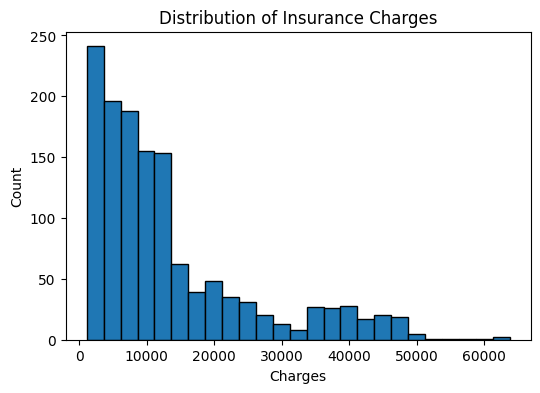

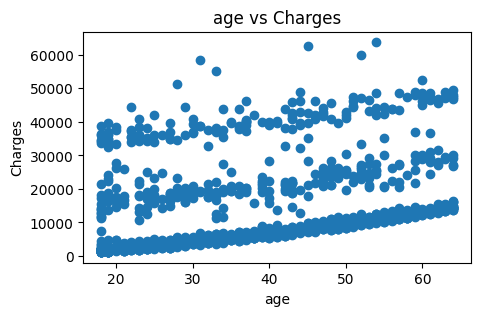

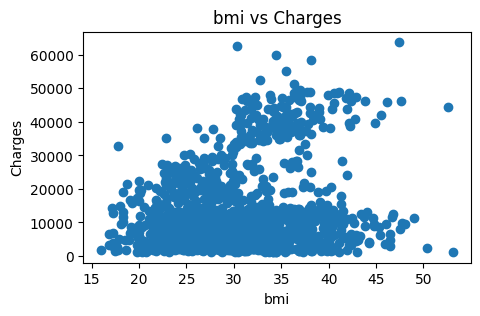

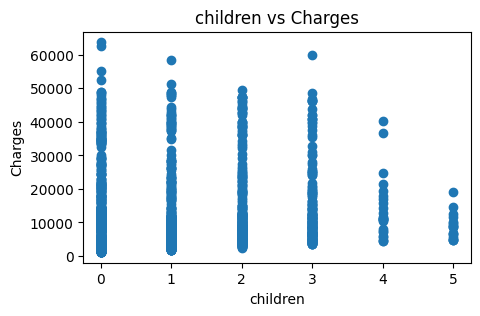

In [3]:
# Distribution of insurance charges
plt.figure(figsize=(6, 4))
plt.hist(df['charges'], bins=25, edgecolor='black')
plt.title('Distribution of Insurance Charges')
plt.xlabel('Charges')
plt.ylabel('Count')
plt.show()

# Relationship between numerical features and charges
for col in ['age', 'bmi', 'children']:
    plt.figure(figsize=(5, 3))
    plt.scatter(df[col], df['charges'])
    plt.title(col + ' vs Charges')
    plt.xlabel(col)
    plt.ylabel('Charges')
    plt.show()

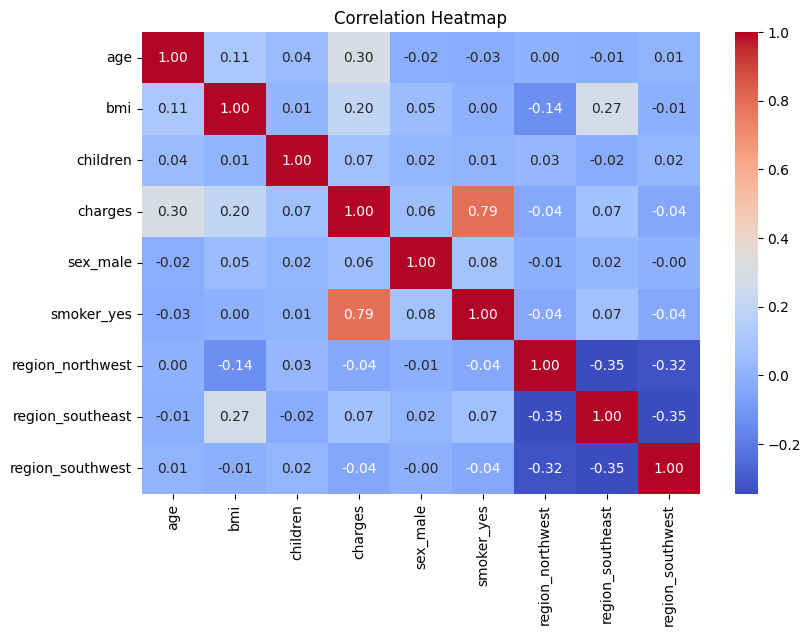

charges             1.000000
smoker_yes          0.787234
age                 0.298308
bmi                 0.198401
region_southeast    0.073578
children            0.067389
sex_male            0.058044
region_northwest   -0.038695
region_southwest   -0.043637
Name: charges, dtype: float64


In [4]:
# Convert categories to numbers for correlation
data_encoded = pd.get_dummies(df, drop_first=True, dtype=int)

plt.figure(figsize=(9, 6))
sns.heatmap(data_encoded.corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

print(data_encoded.corr()['charges'].sort_values(ascending=False))

## 4. Manual calculation using two features


In [5]:
small = df[['age', 'bmi', 'charges']].head(6)

# Add a column of 1s for the intercept
X_small = np.column_stack((np.ones(6), small['age'], small['bmi']))
y_small = small['charges'].values

print("Sample data:")
display(small)

print("Design matrix X:")
print(X_small)

# Normal equation: (X transpose X) b = X transpose y
XTX = X_small.T @ X_small
XTy = X_small.T @ y_small

print("X transpose X:")
print(XTX)
print("X transpose y:")
print(XTy)

# Find b0, b1 and b2
b = np.linalg.solve(XTX, XTy)
print("b0, b1, b2 =", b)

Sample data:


,age,bmi,charges
0,19,27.900,16884.92400
1,18,33.770,1725.55230
2,28,33.000,4449.46200
3,33,22.705,21984.47061
4,32,28.880,3866.85520
5,31,25.740,3756.62160


Design matrix X:
[[ 1.    19.    27.9  ]
 [ 1.    18.    33.77 ]
 [ 1.    28.    33.   ]
 [ 1.    33.    22.705]
 [ 1.    32.    28.88 ]
 [ 1.    31.    25.74 ]]
X transpose X:
[[   6.        161.        171.995   ]
 [ 161.       4543.       4533.325   ]
 [ 171.995    4533.325    5019.941925]]
X transpose y:
[  52667.88571    1442140.59953    1383721.15013105]
b0, b1, b2 = [80066.84597681  -583.44590471 -1940.74478614]


In [6]:
# Predict the first sample and calculate its residual
prediction = b[0] + b[1] * small.iloc[0]['age'] + b[2] * small.iloc[0]['bmi']
actual = small.iloc[0]['charges']

print("Actual charge:", actual)
print("Predicted charge:", prediction)
print("Residual:", actual - prediction)

Actual charge: 16884.924
Predicted charge: 14834.594253953794
Residual: 2050.3297460462054


## 5. Prepare data and split into training and testing sets



In [7]:
X = df.drop('charges', axis=1)
y = df['charges']

# Convert categorical columns into numeric columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Features:", list(X.columns))

Training rows: 1069
Testing rows: 268
Features: ['age', 'bmi', 'children', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']


## 6. Train Simple and Multiple Linear Regression


In [8]:
from sklearn.linear_model import LinearRegression

# Find the numerical feature most related to charges
best_feature = df[['age', 'bmi', 'children', 'charges']].corr()['charges'].drop('charges').abs().idxmax()
print("Feature used in simple regression:", best_feature)

# Simple Linear Regression
simple_model = LinearRegression()
simple_model.fit(X_train[[best_feature]], y_train)

# Multiple Linear Regression
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

print("Simple model intercept:", simple_model.intercept_)
print("Simple model coefficient:", simple_model.coef_[0])

print("\nMultiple model intercept:", multiple_model.intercept_)
for name, value in zip(X.columns, multiple_model.coef_):
    print(name, ":", value)

Feature used in simple regression: age
Simple model intercept: 3534.0917330710636
Simple model coefficient: 242.25815190122503

Multiple model intercept: -11092.65229594595
age : 248.21072022470446
bmi : 318.70144095235077
children : 533.009988798697
sex_male : -101.54205399029631
smoker_yes : 23077.764592868083
region_northwest : -391.7614547836092
region_southeast : -838.9196157269652
region_southwest : -659.1397515529586


## 7. Predict on test data

In [9]:
simple_pred = simple_model.predict(X_test[[best_feature]])
multiple_pred = multiple_model.predict(X_test)

compare = pd.DataFrame({
    'Actual charges': y_test,
    'Simple prediction': simple_pred,
    'Multiple prediction': multiple_pred
})
display(compare.head(10))

,Actual charges,Simple prediction,Multiple prediction
900,8688.85885,15404.741176,8143.693884
1064,5708.86700,10559.578138,5737.115683
1256,11436.73815,15889.257480,14369.314876
298,38746.35510,11044.094442,31745.513636
237,4463.20510,11044.094442,8962.386657
481,9304.70190,15404.741176,13149.722353
240,38511.62830,9106.029227,30446.760679
277,2150.46900,8863.771075,1453.288813
415,7345.72660,13951.192265,10633.018402
707,10264.44210,15404.741176,11318.943794


## 8. Calculate regression metrics
MAE and RMSE show typical error size. R² compares the model with predicting the average target. Adjusted R² penalises unnecessary features.

In [10]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def show_metrics(actual, predicted, number_of_features):
    mae = mean_absolute_error(actual, predicted)
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    n = len(actual)
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - number_of_features - 1)
    return [mae, mse, rmse, r2, adjusted_r2]

simple_scores = show_metrics(y_test, simple_pred, 1)
multiple_scores = show_metrics(y_test, multiple_pred, X_test.shape[1])

results = pd.DataFrame(
    [simple_scores, multiple_scores],
    columns=['MAE', 'MSE', 'RMSE', 'R2', 'Adjusted R2'],
    index=['Simple Regression', 'Multiple Regression']
)
display(results)

,MAE,MSE,RMSE,R2,Adjusted R2
Simple Regression,9657.789350,1.662753e+08,12894.779883,0.095130,0.091728
Multiple Regression,4177.045561,3.547802e+07,5956.342894,0.806929,0.800965


## 9. Residual analysis


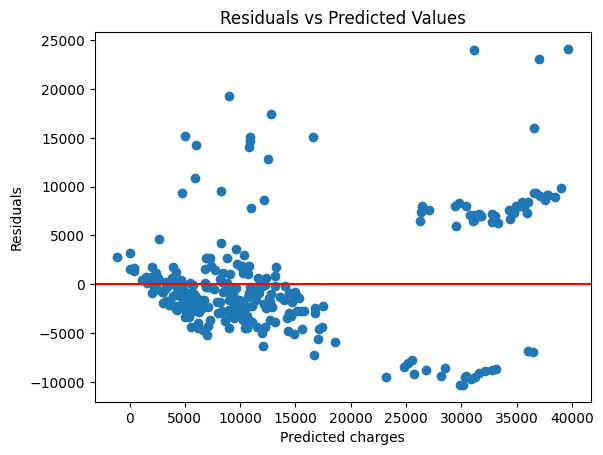

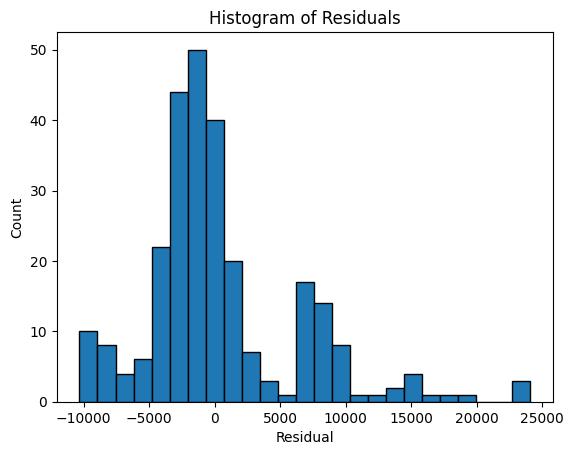

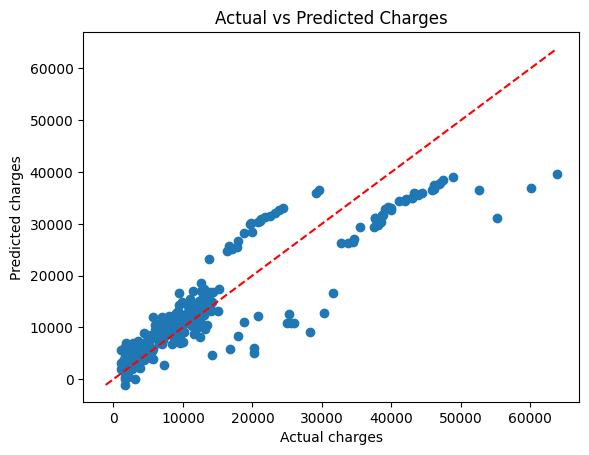

In [11]:
residuals = y_test - multiple_pred

plt.scatter(multiple_pred, residuals)
plt.axhline(0, color='red')
plt.title('Residuals vs Predicted Values')
plt.xlabel('Predicted charges')
plt.ylabel('Residuals')
plt.show()

plt.hist(residuals, bins=25, edgecolor='black')
plt.title('Histogram of Residuals')
plt.xlabel('Residual')
plt.ylabel('Count')
plt.show()

plt.scatter(y_test, multiple_pred)
low = min(y_test.min(), multiple_pred.min())
high = max(y_test.max(), multiple_pred.max())
plt.plot([low, high], [low, high], 'r--')
plt.title('Actual vs Predicted Charges')
plt.xlabel('Actual charges')
plt.ylabel('Predicted charges')
plt.show()

### Check multicollinearity using VIF


In [12]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

X_vif = add_constant(X_train.astype(float))

vif = pd.DataFrame()
vif['Feature'] = X_vif.columns
vif['VIF'] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]
display(vif)

,Feature,VIF
0,const,1.000000
1,age,1.023864
2,bmi,1.110796
3,children,1.004939
4,sex_male,1.011112
5,smoker_yes,1.018267
6,region_northwest,1.542936
7,region_southeast,1.678878
8,region_southwest,1.555261


## 10. Predict for a new customer


In [13]:
new_customer = pd.DataFrame([{
    'age': 35,
    'sex': 'female',
    'bmi': 27.5,
    'children': 1,
    'smoker': 'no',
    'region': 'southwest'
}])

new_customer = pd.get_dummies(new_customer, drop_first=True, dtype=int)

# Make sure new data has exactly the training columns
new_customer = new_customer.reindex(columns=X.columns, fill_value=0)

new_charge = multiple_model.predict(new_customer)
print("Predicted insurance charges:", round(new_charge[0], 2))

Predicted insurance charges: 6892.02
